In [16]:
# %% [0] Load Environment Variables & Test imdb236 Connection
import os
import json
import http.client
from dotenv import load_dotenv

load_dotenv(override=True)
RAPIDAPI_KEY = os.getenv("RAPIDAPI_KEY")

if not RAPIDAPI_KEY:
    raise ValueError("RAPIDAPI_KEY not found in .env")

HOST = "imdb236.p.rapidapi.com"
conn = http.client.HTTPSConnection(HOST)
headers = {
    "x-rapidapi-key": RAPIDAPI_KEY,
    "x-rapidapi-host": HOST
}

conn.request("GET", "/api/imdb/tt0816692", headers=headers)
res = conn.getresponse()
payload = json.loads(res.read().decode("utf-8"))

print(f"HTTP {res.status} | Title: {payload.get('primaryTitle')} ({payload.get('startYear')})")

HTTP 200 | Title: Interstellar (2014)


In [19]:
# %% [Inspect imdb236 Payload Structure]
for k, v in payload.items():
    if isinstance(v, (dict, list)):
        sample = json.dumps(v)[:200]
        print(f"{k} ({type(v).__name__}): {sample}...")
    else:
        print(f"{k}: {v}")

id: tt0816692
url: https://www.imdb.com/title/tt0816692/
primaryTitle: Interstellar
originalTitle: Interstellar
type: movie
parentImdbId: None
description: In a dystopian future where Earth has become near-uninhabitable, a team of astronauts embark on a mission to find a new home for humanity.
primaryImage: https://m.media-amazon.com/images/M/MV5BYzdjMDAxZGItMjI2My00ODA1LTlkNzItOWFjMDU5ZDJlYWY3XkEyXkFqcGc@.jpg
thumbnails (list): [{"url": "https://m.media-amazon.com/images/M/MV5BYzdjMDAxZGItMjI2My00ODA1LTlkNzItOWFjMDU5ZDJlYWY3XkEyXkFqcGc@._V1_QL75_UX100_CR0,0,100,148_.jpg", "width": 100, "height": 148}, {"url": "https://m.medi...
trailer: https://www.youtube.com/watch?v=827FNDpQWrQ
contentRating: PG-13
startYear: 2014
endYear: None
releaseDate: 2014-11-07
interests (list): ["Sci-Fi Epic", "Space Sci-Fi", "Time Travel", "Adventure", "Sci-Fi"]...
countriesOfOrigin (list): ["US", "GB", "CA"]...
externalLinks (list): ["https://www.facebook.com/Interstellar", "https://twitter.com/Interstella

In [21]:
# %% [1] Parse & Flatten imdb236 Movie Payload
import pandas as pd
import numpy as np

def parse_rapidapi_movie(payload: dict) -> dict:
    """
    Flattens the imdb236 /api/imdb/{id} JSON payload into a clean analytical record
    with engineered theatrical financial KPIs.
    """
    budget_amt = payload.get("budget")
    ww_gross = payload.get("grossWorldwide")

    # Engineered Studio Financial KPIs
    # Industry rule of thumb: theatrical break-even is ~2.5x production budget
    est_break_even_usd = (budget_amt * 2.5) if budget_amt else np.nan
    roi_multiple = (ww_gross / budget_amt) if (ww_gross and budget_amt) else np.nan
    net_studio_margin_usd = ((ww_gross * 0.5) - budget_amt) if (ww_gross and budget_amt) else np.nan

    genres = payload.get("genres") or []
    directors = payload.get("directors") or []
    cast = payload.get("cast") or []
    companies = payload.get("productionCompanies") or []
    countries = payload.get("countriesOfOrigin") or []

    return {
        "imdb_id": payload.get("id"),
        "title": payload.get("primaryTitle"),
        "release_date": payload.get("releaseDate"),
        "year": payload.get("startYear"),
        "runtime_minutes": payload.get("runtimeMinutes"),
        "certificate": payload.get("contentRating"),
        "primary_genre": genres[0] if genres else "Unknown",
        "all_genres": ", ".join(genres),
        "origin_country": countries[0] if countries else "Unknown",
        "lead_studio": companies[0].get("name") if companies else "Unknown",
        "imdb_rating": payload.get("averageRating"),
        "vote_count": payload.get("numVotes"),
        "metascore": payload.get("metascore"),
        "directors": ", ".join([d.get("fullName", "") for d in directors]),
        "top_stars": ", ".join([c.get("fullName", "") for c in cast[:4]]),
        "budget_usd": budget_amt,
        "gross_worldwide_usd": ww_gross,
        "est_break_even_usd": est_break_even_usd,
        "roi_multiple": round(roi_multiple, 2) if pd.notna(roi_multiple) else np.nan,
        "est_net_profit_usd": round(net_studio_margin_usd, 2) if pd.notna(net_studio_margin_usd) else np.nan,
        "poster_url": payload.get("primaryImage"),
    }

# Quick sanity check on Interstellar payload
parsed_test = parse_rapidapi_movie(payload)
pd.Series(parsed_test)

imdb_id                                                        tt0816692
title                                                       Interstellar
release_date                                                  2014-11-07
year                                                                2014
runtime_minutes                                                      169
certificate                                                        PG-13
primary_genre                                                  Adventure
all_genres                                             Adventure, Sci-Fi
origin_country                                                        US
lead_studio                                           Paramount Pictures
imdb_rating                                                          8.7
vote_count                                                       2636333
metascore                                                             74
directors                                          

In [23]:
# %% [2] Batch Fetch Top Theatrical Releases via /api/imdb/search & Save to SQLite
import time
import sqlite3
import urllib.parse

def fetch_search_batch(genre: str, rows: int = 50, sort_field: str = "numVotes") -> list[dict]:
    """Queries imdb236 /api/imdb/search for high-visibility theatrical releases."""
    conn = http.client.HTTPSConnection(HOST)
    headers = {
        "x-rapidapi-key": RAPIDAPI_KEY,
        "x-rapidapi-host": HOST
    }
    params = urllib.parse.urlencode({
        "type": "movie",
        "genre": genre,
        "rows": rows,
        "sortField": sort_field,
        "sortOrder": "DESC"
    })
    conn.request("GET", f"/api/imdb/search?{params}", headers=headers)
    res = conn.getresponse()
    raw = res.read().decode("utf-8")
    
    if res.status != 200:
        print(f"Warning [{genre}]: HTTP {res.status} -> {raw[:150]}")
        return []
        
    data = json.loads(raw)
    return data.get("results", []) if isinstance(data, dict) else (data or [])

def build_box_office_db(db_path: str = "box_office.db", rows_per_genre: int = 50):
    """Collects unique movies across core genres and persists them to SQLite."""
    genres = ["Action", "Adventure", "Drama", "Comedy", "Sci-Fi", "Horror", "Animation", "Thriller"]
    seen_ids = set()
    all_records = []

    for genre in genres:
        items = fetch_search_batch(genre=genre, rows=rows_per_genre)
        added = 0
        for item in items:
            mid = item.get("id")
            if not mid or mid in seen_ids:
                continue
            seen_ids.add(mid)
            
            parsed = parse_rapidapi_movie(item)
            # Keep records with valid release date and worldwide box office gross
            if parsed["release_date"] and pd.notna(parsed["gross_worldwide_usd"]):
                all_records.append(parsed)
                added += 1
                
        print(f"Genre '{genre}': fetched {len(items)} items | added {added} valid box-office movies")
        time.sleep(0.35)  # Respect RapidAPI rate limits

    df_movies = pd.DataFrame(all_records)
    
    # Save to SQLite
    db = sqlite3.connect(db_path)
    df_movies.to_sql("movies", db, if_exists="replace", index=False)
    db.close()
    
    print(f"\nSaved {len(df_movies)} unique movies to '{db_path}'.")
    return df_movies

df_movies = build_box_office_db(db_path="box_office.db", rows_per_genre=50)
df_movies[["imdb_id", "title", "release_date", "primary_genre", "budget_usd", "gross_worldwide_usd", "roi_multiple"]].head(10)

Genre 'Action': fetched 50 items | added 50 valid box-office movies
Genre 'Adventure': fetched 50 items | added 23 valid box-office movies
Genre 'Drama': fetched 50 items | added 41 valid box-office movies
Genre 'Comedy': fetched 50 items | added 36 valid box-office movies
Genre 'Sci-Fi': fetched 50 items | added 18 valid box-office movies
Genre 'Horror': fetched 50 items | added 42 valid box-office movies
Genre 'Animation': fetched 50 items | added 34 valid box-office movies
Genre 'Thriller': fetched 50 items | added 32 valid box-office movies

Saved 276 unique movies to 'box_office.db'.


,imdb_id,title,release_date,primary_genre,budget_usd,gross_worldwide_usd,roi_multiple
0,tt0133093,The Matrix,1999-03-31,Action,63000000.0,473333509,7.51
1,tt0172495,Gladiator,2000-05-05,Action,103000000.0,465518644,4.52
2,tt0076759,Star Wars: Episode IV - A New Hope,1977-05-25,Action,11000000.0,775398507,70.49
3,tt0848228,The Avengers,2012-05-04,Action,220000000.0,1520538536,6.91
4,tt0499549,Avatar,2009-12-18,Action,237000000.0,-1371256588,-5.79
5,tt4154796,Avengers: Endgame,2019-04-26,Action,356000000.0,-1352306043,-3.80
6,tt4154756,Avengers: Infinity War,2018-04-27,Action,350000000.0,2052415039,5.86
7,tt2015381,Guardians of the Galaxy,2014-08-01,Action,170000000.0,773350376,4.55
8,tt0110413,Léon: The Professional,1994-11-18,Action,16000000.0,20332654,1.27
9,tt0325980,Pirates of the Caribbean: The Curse of the Bla...,2003-07-09,Action,140000000.0,654270874,4.67


In [25]:
# %% [3] Patch 32-Bit Integer Overflow & Expand Dense 2010–2025 Coverage
def fix_int32_overflow(val):
    """Restores true box office gross when API 32-bit signed int wraps negative (> $2.147B)."""
    if pd.notna(val) and val < 0:
        return float(val + 4_294_967_296)
    return val

# 1. Fix the existing 276 rows in SQLite first
db = sqlite3.connect("box_office.db")
df_existing = pd.read_sql("SELECT * FROM movies", db)
df_existing["gross_worldwide_usd"] = df_existing["gross_worldwide_usd"].apply(fix_int32_overflow)
df_existing["roi_multiple"] = np.round(df_existing["gross_worldwide_usd"] / df_existing["budget_usd"], 2)
df_existing["est_net_profit_usd"] = np.round((df_existing["gross_worldwide_usd"] * 0.5) - df_existing["budget_usd"], 2)

seen_ids = set(df_existing["imdb_id"].dropna())
new_records = []

# 2. Fetch top 50 theatrical releases per year (2010–2025) for dense monthly continuity
for yr in range(2010, 2026):
    conn = http.client.HTTPSConnection(HOST)
    headers = {"x-rapidapi-key": RAPIDAPI_KEY, "x-rapidapi-host": HOST}
    params = urllib.parse.urlencode({
        "type": "movie",
        "startYearFrom": yr,
        "startYearTo": yr,
        "rows": 50,
        "sortField": "numVotes",
        "sortOrder": "DESC"
    })
    conn.request("GET", f"/api/imdb/search?{params}", headers=headers)
    res = conn.getresponse()
    if res.status == 200:
        data = json.loads(res.read().decode("utf-8"))
        items = data.get("results", []) if isinstance(data, dict) else (data or [])
        added = 0
        for item in items:
            mid = item.get("id")
            if not mid or mid in seen_ids:
                continue
            seen_ids.add(mid)
            parsed = parse_rapidapi_movie(item)
            if parsed["release_date"] and pd.notna(parsed["gross_worldwide_usd"]):
                parsed["gross_worldwide_usd"] = fix_int32_overflow(parsed["gross_worldwide_usd"])
                if pd.notna(parsed["budget_usd"]) and parsed["budget_usd"] > 0:
                    parsed["roi_multiple"] = round(parsed["gross_worldwide_usd"] / parsed["budget_usd"], 2)
                    parsed["est_net_profit_usd"] = round((parsed["gross_worldwide_usd"] * 0.5) - parsed["budget_usd"], 2)
                new_records.append(parsed)
                added += 1
        print(f"Year {yr}: added {added} new movies")
    time.sleep(0.35)

df_all = pd.concat([df_existing, pd.DataFrame(new_records)], ignore_index=True)
df_all.to_sql("movies", db, if_exists="replace", index=False)
db.close()

print(f"\nTotal clean movies in SQLite: {len(df_all)}")
print(df_all[df_all["title"].isin(["Avatar", "Avengers: Endgame"])][["title", "gross_worldwide_usd", "roi_multiple"]])

Year 2010: added 41 new movies
Year 2011: added 40 new movies
Year 2012: added 38 new movies
Year 2013: added 38 new movies
Year 2014: added 32 new movies
Year 2015: added 41 new movies
Year 2016: added 36 new movies
Year 2017: added 40 new movies
Year 2018: added 39 new movies
Year 2019: added 36 new movies
Year 2020: added 33 new movies
Year 2021: added 41 new movies
Year 2022: added 40 new movies
Year 2023: added 43 new movies
Year 2024: added 44 new movies
Year 2025: added 44 new movies

Total clean movies in SQLite: 902
               title  gross_worldwide_usd  roi_multiple
4             Avatar         2.923711e+09         12.34
5  Avengers: Endgame         2.942661e+09          8.27


Time series span: 2010-01-01 to 2025-12-01 (192 months)
  month_date  release_count  total_gross_musd  avg_gross_per_movie_musd  \
0 2010-01-01              1        157.107755                157.107755   
1 2010-02-01              2        521.475746                260.737873   
2 2010-03-01              3       1585.128289                528.376096   
3 2010-04-01              2        589.403896                294.701948   
4 2010-05-01              3       1281.968748                427.322916   

   total_budget_musd  avg_imdb_rating  
0               80.0         6.800000  
1              175.0         7.050000  
2              401.0         6.966667  
3              155.0         6.700000  
4              600.0         6.666667  

--- Stationarity Diagnostics ---
ADF [Raw Monthly Gross ($M)  ] | Stat:  -2.305 | p-value: 0.1705 -> NON-STATIONARY (Fail to reject H0)
ADF [1st Differenced Gross   ] | Stat:  -5.216 | p-value: 0.0000 -> STATIONARY (Reject H0)


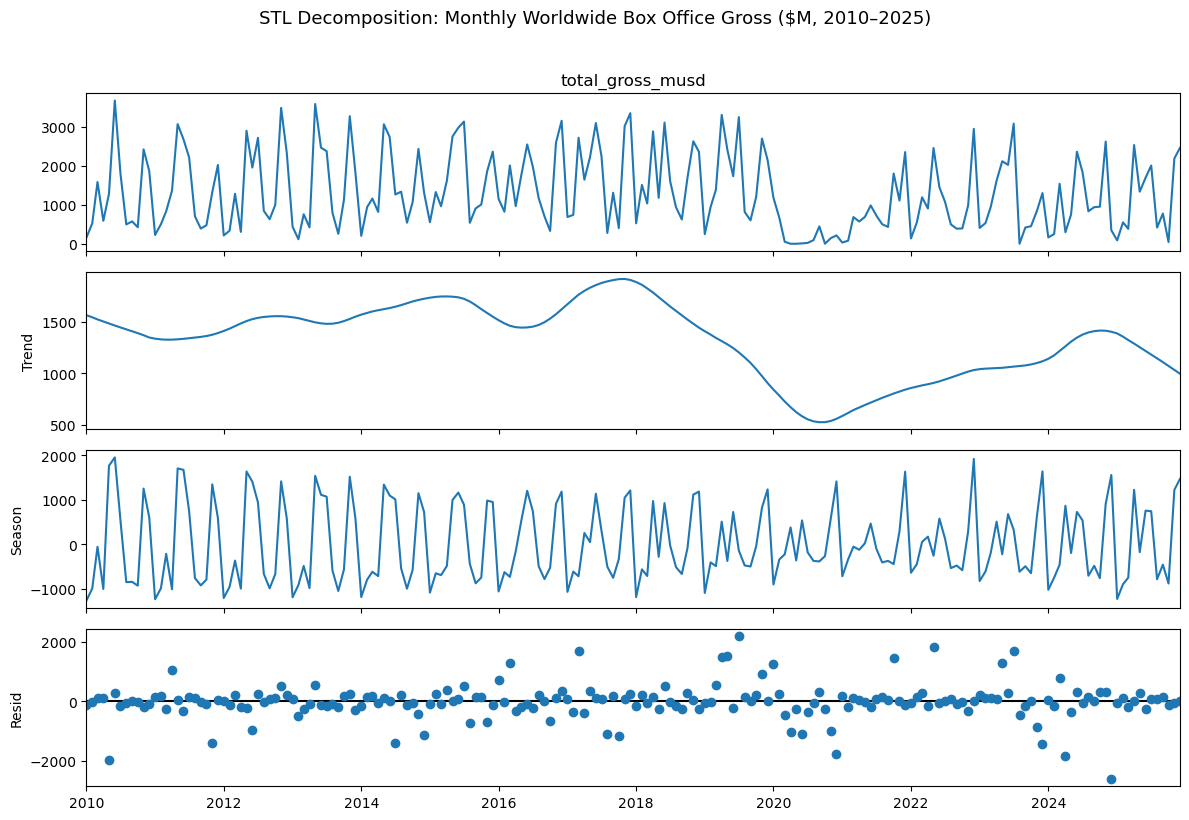

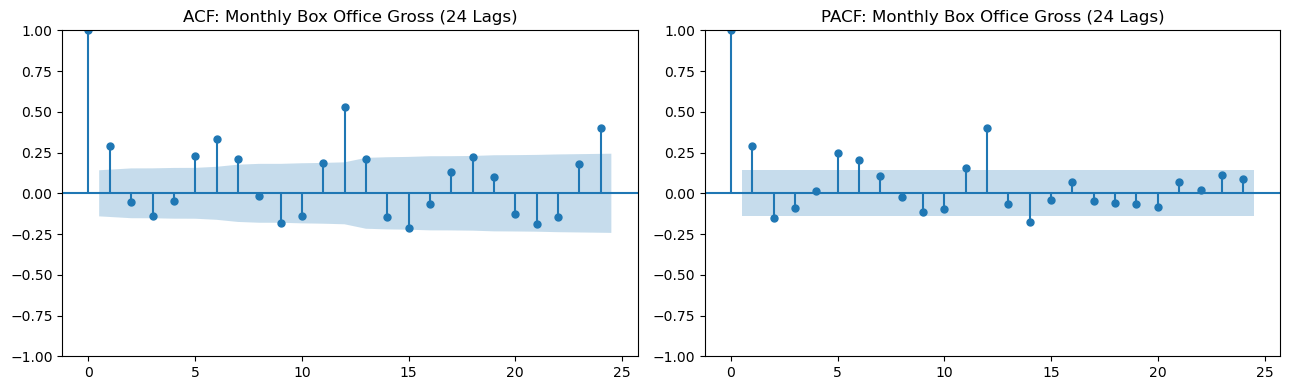

In [27]:
# %% [4] SQL Monthly Aggregation & Statistical Diagnostics (STL, ADF, ACF/PACF)
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Aggregate movie releases into a continuous Monthly Box Office Time Series via SQL
db = sqlite3.connect("box_office.db")
query = """
SELECT
    strftime('%Y-%m-01', release_date) AS month_date,
    COUNT(*) AS release_count,
    SUM(gross_worldwide_usd) / 1e6 AS total_gross_musd,
    AVG(gross_worldwide_usd) / 1e6 AS avg_gross_per_movie_musd,
    SUM(COALESCE(budget_usd, 0)) / 1e6 AS total_budget_musd,
    AVG(imdb_rating) AS avg_imdb_rating
FROM movies
WHERE release_date >= '2010-01-01'
  AND release_date <= '2025-12-31'
GROUP BY 1
ORDER BY 1 ASC;
"""
df_ts = pd.read_sql(query, db)
db.close()

# Ensure continuous monthly index (fill any missing month with 0)
df_ts["month_date"] = pd.to_datetime(df_ts["month_date"])
full_idx = pd.date_range("2010-01-01", "2025-12-01", freq="MS")
df_ts = (
    df_ts.set_index("month_date")
    .reindex(full_idx, fill_value=0)
    .rename_axis("month_date")
    .reset_index()
)

print(f"Time series span: {df_ts['month_date'].min().date()} to {df_ts['month_date'].max().date()} ({len(df_ts)} months)")
print(df_ts.head())

# 2. Augmented Dickey-Fuller (ADF) Stationarity Test (Raw vs. 1st Difference)
def run_adf_test(series: pd.Series, name: str):
    stat, p_val, _, _, crit, _ = adfuller(series.dropna())
    status = "STATIONARY (Reject H0)" if p_val < 0.05 else "NON-STATIONARY (Fail to reject H0)"
    print(f"ADF [{name:24s}] | Stat: {stat:7.3f} | p-value: {p_val:.4f} -> {status}")

print("\n--- Stationarity Diagnostics ---")
run_adf_test(df_ts["total_gross_musd"], "Raw Monthly Gross ($M)")
run_adf_test(df_ts["total_gross_musd"].diff(1), "1st Differenced Gross")

# 3. STL Seasonal Decomposition (Period = 12 months)
stl = STL(df_ts.set_index("month_date")["total_gross_musd"], period=12, robust=True)
res_stl = stl.fit()

fig = res_stl.plot()
fig.set_size_inches(12, 8)
fig.suptitle("STL Decomposition: Monthly Worldwide Box Office Gross ($M, 2010–2025)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# 4. ACF & PACF Plots (24 Monthly Lags)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(df_ts["total_gross_musd"], lags=24, ax=axes[0], title="ACF: Monthly Box Office Gross (24 Lags)")
plot_pacf(df_ts["total_gross_musd"], lags=24, ax=axes[1], method="ywm", title="PACF: Monthly Box Office Gross (24 Lags)")
plt.tight_layout()
plt.show()

In [31]:
'''%pip install xgboost'''

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 364.6 kB/s eta 0:02:13
   ---------------------------------------- 0.5/48.9 MB 364.6 kB/s eta 0:02:13
   ---------------------------------------- 0.5/48.9 MB 364.6 kB/s eta 0:02:13
   ---------------------------------------- 0.5/48.9 MB 364.6 kB/s eta 0:02:13
    --------------------------------------- 0.8/48.9 MB 349.5 kB/s eta 0:02:18
    --------------------------------------- 0.8/48.9 MB 349.5 kB/s eta 0:02:18
    ------------------------

In [33]:
# %% [5] Feature Engineering, 5-Fold Walk-Forward Validation & Business Cost Engine
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

# 1. Engineer Leak-Free Time Series Features
def build_monthly_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy().sort_values("month_date").reset_index(drop=True)
    
    # Calendar & Cyclical Features
    d["month"] = d["month_date"].dt.month
    d["quarter"] = d["month_date"].dt.quarter
    d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
    d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
    
    # Structural Break Indicator (COVID-19 Theater Closures: Mar 2020 – Jun 2021)
    d["is_covid_shock"] = ((d["month_date"] >= "2020-03-01") & (d["month_date"] <= "2021-06-01")).astype(int)
    
    # ACF-Backed Lags (1-month momentum, 6-month half-year, 12-month & 24-month annual)
    for lag in [1, 2, 3, 6, 12, 24]:
        d[f"lag_{lag}"] = d["total_gross_musd"].shift(lag)
        
    # Leak-Free Shifted Rolling Statistics (shift(1) before rolling!)
    shifted = d["total_gross_musd"].shift(1)
    for win in [3, 6, 12]:
        d[f"roll_mean_{win}"] = shifted.rolling(win).mean()
        d[f"roll_std_{win}"] = shifted.rolling(win).std()
        
    # Lagged Release Pipeline Volume (known prior to month start)
    d["lag_1_releases"] = d["release_count"].shift(1)
    d["lag_12_releases"] = d["release_count"].shift(12)
    
    return d.dropna().reset_index(drop=True)

df_model = build_monthly_features(df_ts)
print(f"Engineered dataset shape: {df_model.shape} (2012-01 to 2025-12)")

# 2. Asymmetric Theatrical Operational Cost ($M)
def theatrical_planning_cost(y_true: np.ndarray, y_pred: np.ndarray,
                             under_rate: float = 0.35, over_rate: float = 0.10) -> float:
    """
    - Under-forecasting (y_true > y_pred): $0.35M lost distributor/theater capture per $1M missed.
    - Over-forecasting (y_pred > y_true): $0.10M excess screen/marketing overhead per $1M over-projected.
    """
    diff = y_true - y_pred
    under_err = np.maximum(0, diff)
    over_err = np.maximum(0, -diff)
    return float(np.sum(under_err * under_rate + over_err * over_rate))

# 3. Expanding-Window Walk-Forward Cross-Validation (5 Folds, 6-Month Forecast Horizon)
tscv = TimeSeriesSplit(n_splits=5, test_size=6)
feature_cols = [c for c in df_model.columns if c not in [
    "month_date", "total_gross_musd", "release_count",
    "avg_gross_per_movie_musd", "total_budget_musd", "avg_imdb_rating"
]]

cv_results = []
oof_predictions = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(df_model), 1):
    train_df, val_df = df_model.iloc[train_idx], df_model.iloc[val_idx]
    X_train, y_train = train_df[feature_cols], train_df["total_gross_musd"].values
    X_val, y_val = val_df[feature_cols], val_df["total_gross_musd"].values
    
    # Tier 1: Seasonal Naive (Same month prior year)
    pred_naive = val_df["lag_12"].values
    
    # Tier 2: SARIMAX (1,1,1)x(1,1,0,12) with COVID exogenous flag
    sarimax = SARIMAX(
        train_df["total_gross_musd"],
        exog=train_df[["is_covid_shock"]],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)
    pred_sarimax = np.maximum(0, sarimax.forecast(steps=len(val_df), exog=val_df[["is_covid_shock"]]).values)
    
    # Tier 3: XGBoost Point Forecast + 90% Prediction Intervals (5th & 95th Quantiles)
    xgb_point = XGBRegressor(
        n_estimators=250, learning_rate=0.04, max_depth=3,
        subsample=0.8, colsample_bytree=0.8, random_state=42
    )
    xgb_point.fit(X_train, y_train)
    pred_xgb = np.maximum(0, xgb_point.predict(X_val))
    
    xgb_low = XGBRegressor(n_estimators=200, learning_rate=0.04, max_depth=3,
                           objective="reg:quantileerror", quantile_alpha=0.05, random_state=42)
    xgb_high = XGBRegressor(n_estimators=200, learning_rate=0.04, max_depth=3,
                            objective="reg:quantileerror", quantile_alpha=0.95, random_state=42)
    xgb_low.fit(X_train, y_train)
    xgb_high.fit(X_train, y_train)
    
    cv_results.append({
        "Fold": fold,
        "Period": f"{val_df['month_date'].min().strftime('%Y-%m')}..{val_df['month_date'].max().strftime('%Y-%m')}",
        "Naive_MAE ($M)": round(mean_absolute_error(y_val, pred_naive), 1),
        "SARIMAX_MAE ($M)": round(mean_absolute_error(y_val, pred_sarimax), 1),
        "XGB_MAE ($M)": round(mean_absolute_error(y_val, pred_xgb), 1),
        "Naive_Cost ($M)": round(theatrical_planning_cost(y_val, pred_naive), 1),
        "SARIMAX_Cost ($M)": round(theatrical_planning_cost(y_val, pred_sarimax), 1),
        "XGB_Cost ($M)": round(theatrical_planning_cost(y_val, pred_xgb), 1),
    })
    
    fold_preds = val_df[["month_date", "total_gross_musd"]].copy()
    fold_preds["Fold"] = fold
    fold_preds["Naive_Pred"] = pred_naive
    fold_preds["SARIMAX_Pred"] = pred_sarimax
    fold_preds["XGB_Pred"] = pred_xgb
    fold_preds["XGB_Lower_90"] = np.maximum(0, xgb_low.predict(X_val))
    fold_preds["XGB_Upper_90"] = np.maximum(pred_xgb, xgb_high.predict(X_val))
    oof_predictions.append(fold_preds)

df_cv = pd.DataFrame(cv_results)
df_oof = pd.concat(oof_predictions, ignore_index=True)

print("\n=== 5-Fold Walk-Forward Validation Results ===")
print(df_cv.to_string(index=False))

print("\n=== Average Performance Across All 5 Folds ===")
summary = df_cv[["Naive_MAE ($M)", "SARIMAX_MAE ($M)", "XGB_MAE ($M)",
                 "Naive_Cost ($M)", "SARIMAX_Cost ($M)", "XGB_Cost ($M)"]].mean().round(2)
print(summary)

Engineered dataset shape: (168, 25) (2012-01 to 2025-12)

=== 5-Fold Walk-Forward Validation Results ===
 Fold           Period  Naive_MAE ($M)  SARIMAX_MAE ($M)  XGB_MAE ($M)  Naive_Cost ($M)  SARIMAX_Cost ($M)  XGB_Cost ($M)
    1 2023-07..2023-12           732.2             755.2         899.5            963.4             1085.6         1002.2
    2 2024-01..2024-06           691.5             656.9         777.0            648.2              719.5          711.9
    3 2024-07..2024-12           974.6             956.2         541.7           1495.9             1604.3          689.8
    4 2025-01..2025-06           837.9             661.3         635.1           1284.0              988.3          774.0
    5 2025-07..2025-12           702.1             538.8         613.6            993.3              890.1          921.5

=== Average Performance Across All 5 Folds ===
Naive_MAE ($M)        787.66
SARIMAX_MAE ($M)      713.68
XGB_MAE ($M)          693.38
Naive_Cost ($M)      1076.96

In [35]:
# %% [6] Inspect 5-Fold Benchmark Results & Export Artifacts for Dashboard
print("=== 5-Fold Walk-Forward Validation Results ===")
print(df_cv.to_string(index=False))

print("\n=== Average Performance Across All 5 Folds ===")
summary = df_cv[[
    "Naive_MAE ($M)", "SARIMAX_MAE ($M)", "XGB_MAE ($M)",
    "Naive_Cost ($M)", "SARIMAX_Cost ($M)", "XGB_Cost ($M)"
]].mean().round(2)
print(summary)

# Save clean tables for Streamlit / Power BI consumption
df_ts.to_csv("monthly_box_office_ts.csv", index=False)
df_cv.to_csv("walk_forward_cv_metrics.csv", index=False)
df_oof.to_csv("oof_predictions.csv", index=False)
print("\nExported monthly_box_office_ts.csv, walk_forward_cv_metrics.csv, and oof_predictions.csv.")

=== 5-Fold Walk-Forward Validation Results ===
 Fold           Period  Naive_MAE ($M)  SARIMAX_MAE ($M)  XGB_MAE ($M)  Naive_Cost ($M)  SARIMAX_Cost ($M)  XGB_Cost ($M)
    1 2023-07..2023-12           732.2             755.2         899.5            963.4             1085.6         1002.2
    2 2024-01..2024-06           691.5             656.9         777.0            648.2              719.5          711.9
    3 2024-07..2024-12           974.6             956.2         541.7           1495.9             1604.3          689.8
    4 2025-01..2025-06           837.9             661.3         635.1           1284.0              988.3          774.0
    5 2025-07..2025-12           702.1             538.8         613.6            993.3              890.1          921.5

=== Average Performance Across All 5 Folds ===
Naive_MAE ($M)        787.66
SARIMAX_MAE ($M)      713.68
XGB_MAE ($M)          693.38
Naive_Cost ($M)      1076.96
SARIMAX_Cost ($M)    1057.56
XGB_Cost ($M)         819.88

In [39]:
# %% [7] Retrain on Full History & Generate 6-Month Recursive Future Forecast (2026-01 to 2026-06)

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Bypasses Windows loky physical core subprocess lookup

from sklearn.ensemble import HistGradientBoostingRegressor

# 1. Fit Final Models on Complete Engineered Dataset (2012-01 to 2025-12)
X_full = df_model[feature_cols]
y_full = df_model["total_gross_musd"].values

final_point = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.04, max_depth=3, random_state=42)
final_low = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.04, max_depth=3, loss="quantile", quantile=0.05, random_state=42)
final_high = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.04, max_depth=3, loss="quantile", quantile=0.95, random_state=42)

final_point.fit(X_full, y_full)
final_low.fit(X_full, y_full)
final_high.fit(X_full, y_full)

# 2. Recursive Step-by-Step Forecasting for 2026-01 to 2026-06
history_df = df_ts.copy()
future_dates = pd.date_range("2026-01-01", periods=6, freq="MS")
future_rows = []

for f_date in future_dates:
    # Append placeholder row for target month
    new_row = pd.DataFrame({
        "month_date": [f_date],
        "release_count": [history_df["release_count"].iloc[-12]],  # Seasonal prior year release count
        "total_gross_musd": [np.nan],
        "avg_gross_per_movie_musd": [0.0],
        "total_budget_musd": [0.0],
        "avg_imdb_rating": [0.0]
    })
    temp_df = pd.concat([history_df, new_row], ignore_index=True)
    
    # Recompute features up to f_date
    temp_feat = build_monthly_features(temp_df.iloc[:-1])  # Historical rows
    # Build single feature row for f_date manually using temp_df history
    d = temp_df.copy()
    d["month"] = d["month_date"].dt.month
    d["quarter"] = d["month_date"].dt.quarter
    d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
    d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
    d["is_covid_shock"] = 0
    for lag in [1, 2, 3, 6, 12, 24]:
        d[f"lag_{lag}"] = d["total_gross_musd"].shift(lag)
    shifted = d["total_gross_musd"].shift(1)
    for win in [3, 6, 12]:
        d[f"roll_mean_{win}"] = shifted.rolling(win).mean()
        d[f"roll_std_{win}"] = shifted.rolling(win).std()
    d["lag_1_releases"] = d["release_count"].shift(1)
    d["lag_12_releases"] = d["release_count"].shift(12)
    
    X_next = d.iloc[[-1]][feature_cols]
    pred_p = float(np.maximum(0, final_point.predict(X_next)[0]))
    pred_l = float(np.maximum(0, final_low.predict(X_next)[0]))
    pred_h = float(np.maximum(pred_p, final_high.predict(X_next)[0]))
    
    # Feed predicted gross back into history_df for next recursive step
    new_row["total_gross_musd"] = pred_p
    history_df = pd.concat([history_df, new_row], ignore_index=True)
    
    future_rows.append({
        "month_date": f_date,
        "Forecast_Gross ($M)": round(pred_p, 2),
        "Lower_90_CI ($M)": round(pred_l, 2),
        "Upper_90_CI ($M)": round(pred_h, 2)
    })

df_future = pd.DataFrame(future_rows)
df_future.to_csv("future_forecast_6m.csv", index=False)
print("=== 6-Month Recursive Box Office Forecast (2026-01 to 2026-06) ===")
print(df_future.to_string(index=False))

=== 6-Month Recursive Box Office Forecast (2026-01 to 2026-06) ===
month_date  Forecast_Gross ($M)  Lower_90_CI ($M)  Upper_90_CI ($M)
2026-01-01               476.02            226.23           1140.20
2026-02-01               898.02            135.56           1232.47
2026-03-01              1244.20            412.02           2022.75
2026-04-01              2222.53            686.99           2547.35
2026-05-01              1087.65            403.36           2167.38
2026-06-01              1700.77            729.23           3086.34
